# Historische Wirtschaft, Handel und Militär: Datenaufbereitung

Dieses Notebook importiert **alle zehn gelieferten Datensätze** und bereitet sie für H1, H2, H3, H4 und H8 vor. Es berechnet **noch keine Korrelationen oder p-Werte**. Die Originaldateien bleiben unverändert.

**Ablage:** Dieses Notebook und der Ordner `Data` liegen im selben Verzeichnis. Die Dateinamen in `Data` enthalten **kein `(1)`**. Alle Pfade sind relativ, es werden keine Daten aus dem Internet nachgeladen.

**Bedienung:** In Jupyter `Kernel → Restart Kernel and Run All Cells` wählen. Falls der Kernel in einem anderen Verzeichnis startet, `PROJECT_DIR` in Abschnitt 1 anpassen. Etwa 1–2 GB freier Arbeitsspeicher sind hilfreich. Die große Handelsdatei wird vollständig geladen.

**Pakete:** pandas, numpy, openpyxl und xlrd. Falls erforderlich, die Installationszeile im nächsten Abschnitt ausführen. Für die Aufbereitung werden scipy und seaborn noch nicht benötigt.

**Wichtig:** Die Länderzuordnung ist transparent und ohne unscharfe Namenssuche. Bekannte historische Gebietswechsel werden konservativ ausgeschlossen oder zur Prüfung markiert. Dies ist keine umfassende historische Harmonisierung. Vor einer wissenschaftlichen Interpretation müssen Quellenabdeckung und Vergleichbarkeit geprüft werden. Viele Jahre/Staatenpaare sind statistisch abhängig; große Zeilenzahlen bedeuten nicht entsprechend viele unabhängige Beobachtungen.


In [28]:
# Bei fehlenden Paketen diese Zeile in Jupyter entkommentieren:
# %pip install pandas numpy openpyxl xlrd

from pathlib import Path
import hashlib
import re
import unicodedata
import importlib.util
import numpy as np
import pandas as pd
from IPython.display import display

required_packages = ['openpyxl', 'xlrd']
missing_packages = [p for p in required_packages if importlib.util.find_spec(p) is None]
if missing_packages:
    raise ImportError('Bitte zuerst installieren: ' + ', '.join(missing_packages))

PROJECT_DIR = Path.cwd()  # Notebook liegt auf derselben Ebene wie Data/
DATA_DIR = PROJECT_DIR / 'Data'
START_YEAR, END_YEAR = 1950, 2014
DISTANCE_COLUMN = 'distw'  # bevölkerungsgewichtete geografische Distanz, km

# Qualitätsschwellen sind Annahmen, keine Garantie vollständiger Handelsdaten.
# Kein Ergebnis wird anhand seines Korrelationsvorzeichens ausgewählt.
COVERAGE_MIN, COVERAGE_MAX = 0.90, 1.10
DISTANCE_COVERAGE_MIN = 0.95
MIN_PAIRS = 5000
EXPORT_PREPARED = True  # True schreibt CSV-Dateien nach Prepared/; Originale bleiben erhalten.

FILES = {
    'nmc': 'NMC-70-abridged.csv',
    'national_trade': 'National_COW_4.0.csv',
    'dyadic_trade': 'Dyadic_COW_4.0.csv',
    'state_list': 'statelist2024.csv',
    'geography': 'geo_cepii.xls',
    'distance': 'dist_cepii.xls',
    'maddison': 'mpd2023_web.xlsx',
    'sipri': 'SIPRI-Milex-data-1949-2025_v1.2.xlsx',
    'pwt': 'pwt110.xlsx',
    'wars': 'Inter-StateWarData_v4.0.csv',
}
missing_files = [name for name in FILES.values() if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Gesucht wird in {DATA_DIR.resolve()}. Fehlende Dateien: {missing_files}')

pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 20)
print('Datenordner:', DATA_DIR.resolve())


Datenordner: /Users/jannis.hardt/Documents/VS Code/Integrationsseminar/Data


## 2. Alle Originaldaten importieren

`raw` enthält die unveränderten eingelesenen Tabellen. SIPRI wird zunächst mit allen Textmarkierungen gelesen. PWT verwendet das Blatt `Data`, Maddison `Full data`; regionale Summen werden nicht mit Ländern vermischt. `metadata` bewahrt Legenden und Quellenhinweise auf. Hashwerte helfen, genau die verwendeten Dateien zu dokumentieren.


In [29]:
raw = {}
for key in ['nmc', 'national_trade', 'dyadic_trade', 'state_list', 'wars']:
    raw[key] = pd.read_csv(DATA_DIR / FILES[key], low_memory=False)
raw['geography'] = pd.read_excel(DATA_DIR / FILES['geography'], engine='xlrd')
raw['distance'] = pd.read_excel(DATA_DIR / FILES['distance'], engine='xlrd')
raw['pwt'] = pd.read_excel(DATA_DIR / FILES['pwt'], sheet_name='Data', engine='openpyxl')
raw['maddison'] = pd.read_excel(DATA_DIR / FILES['maddison'], sheet_name='Full data', engine='openpyxl')
raw['sipri'] = pd.read_excel(DATA_DIR / FILES['sipri'], sheet_name='Constant (2024) US$', header=5, engine='openpyxl')
metadata = {
    'pwt_legend': pd.read_excel(DATA_DIR / FILES['pwt'], sheet_name='Legend'),
    'pwt_info': pd.read_excel(DATA_DIR / FILES['pwt'], sheet_name='Info', header=None),
    'maddison_notes': pd.read_excel(DATA_DIR / FILES['maddison'], sheet_name='Notes', header=None),
    'maddison_sources': pd.read_excel(DATA_DIR / FILES['maddison'], sheet_name='Sources', header=None),
    'sipri_footnotes': pd.read_excel(DATA_DIR / FILES['sipri'], sheet_name='Footnotes', header=None),
}

def sha256_file(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

source_catalog = pd.DataFrame([
    {'dataset': key, 'filename': filename, 'rows': len(raw[key]),
     'columns': len(raw[key].columns), 'sha256': sha256_file(DATA_DIR / filename)}
    for key, filename in FILES.items()
])
display(source_catalog[['dataset', 'filename', 'rows', 'columns']])


,dataset,filename,rows,columns
0,nmc,NMC-70-abridged.csv,17121,11
1,national_trade,National_COW_4.0.csv,14410,11
2,dyadic_trade,Dyadic_COW_4.0.csv,886828,23
3,state_list,statelist2024.csv,244,10
4,geography,geo_cepii.xls,238,34
5,distance,dist_cepii.xls,50176,14
6,maddison,mpd2023_web.xlsx,131144,6
7,sipri,SIPRI-Milex-data-1949-2025_v1.2.xlsx,193,80
8,pwt,pwt110.xlsx,13690,51
9,wars,Inter-StateWarData_v4.0.csv,337,25


## 3. Hilfsfunktionen und Bereinigung

Negative fehlende-Werte-Codes werden **nur in dokumentierten Messwertfeldern** entfernt. Echte Nullwerte bleiben erhalten. Kennungen, Quellencodes und Kategorien werden nicht pauschal umcodiert. Negative BIP-/Bevölkerungswerte sind ungültig; jährliche Wachstumsraten dürfen später negativ sein.

Primärschlüssel werden geprüft. Das Notebook stoppt bei widersprüchlichen Duplikaten, statt sie stillschweigend zu löschen.


In [30]:
def require_unique(df, keys, label):
    duplicates = df.duplicated(keys, keep=False)
    if duplicates.any():
        display(df.loc[duplicates, keys].head(10))
        raise ValueError(f'{label}: {int(duplicates.sum())} doppelte Schlüssel für {keys}.')

def numeric_measure(df, columns, nonnegative=True):
    result = df.copy()
    for col in columns:
        result[col] = pd.to_numeric(result[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
        if nonnegative:
            result.loc[result[col] < 0, col] = np.nan
    return result

def normalize_name(name):
    if pd.isna(name):
        return ''
    name = unicodedata.normalize('NFKD', str(name)).encode('ascii', 'ignore').decode()
    return re.sub(r'[^a-z0-9]+', '', name.lower().replace('&', 'and'))

nmc = numeric_measure(raw['nmc'], ['milex', 'milper', 'irst', 'pec', 'tpop', 'upop', 'cinc'])
national_trade = numeric_measure(raw['national_trade'], ['imports', 'exports', 'alt_imports', 'alt_exports'])
dyadic_trade = numeric_measure(raw['dyadic_trade'], ['flow1', 'flow2', 'smoothflow1', 'smoothflow2', 'smoothtotrade',
    'bel_lux_alt_flow1','bel_lux_alt_flow2','china_alt_flow1','china_alt_flow2'])
state_list = raw['state_list'].copy()
pwt = numeric_measure(raw['pwt'], ['rgdpo', 'rgdpe', 'cgdpe', 'pop', 'emp'])
pwt = pwt.rename(columns={'countrycode': 'iso3', 'country': 'pwt_country'})
maddison = numeric_measure(raw['maddison'], ['gdppc', 'pop'])
maddison = maddison.rename(columns={'countrycode': 'iso3', 'country': 'maddison_country',
                                    'pop': 'maddison_population_thousands'})
geo_locations = raw['geography'].copy()  # Mehrere Städte je Land sind absichtlich vorhanden.
distances = numeric_measure(raw['distance'], ['dist', 'distcap', 'distw', 'distwces'])
distances = distances.rename(columns={'iso_o': 'iso3_origin', 'iso_d': 'iso3_destination'})
for df in [pwt, maddison, geo_locations]:
    df['iso3'] = df['iso3'].astype('string').str.strip().str.upper()
for col in ['iso3_origin', 'iso3_destination']:
    distances[col] = distances[col].astype('string').str.strip().str.upper()

# Echte Umbenennungen desselben Landes, keine Zuordnung von Nachfolgestaaten.
# YUG wird ausdrücklich NICHT zu SRB, SUN NICHT zu RUS.
CEPII_CODE_RENAMES = {'ROM':'ROU','TMP':'TLS','ZAR':'COD'}
geo_locations['cepii_iso3_original'] = geo_locations['iso3']
geo_locations['iso3'] = geo_locations['iso3'].replace(CEPII_CODE_RENAMES)
for col in ['iso3_origin','iso3_destination']:
    distances['cepii_'+col+'_original'] = distances[col]
    distances[col] = distances[col].replace(CEPII_CODE_RENAMES)

for df, keys, label in [
    (nmc, ['ccode', 'year'], 'NMC'),
    (national_trade, ['ccode', 'year'], 'National trade'),
    (dyadic_trade, ['ccode1', 'ccode2', 'year'], 'Dyadic trade'),
    (pwt, ['iso3', 'year'], 'PWT'),
    (maddison, ['iso3', 'year'], 'Maddison'),
    (distances, ['iso3_origin', 'iso3_destination'], 'CEPII distances')]:
    require_unique(df, keys, label)

# Eine Länderübersicht ohne willkürliche Wahl einer Hauptstadtkoordinate.
# Stadtkoordinaten bleiben ausschließlich in geo_locations.
geo_country_fields = ['iso3', 'country', 'area', 'landlocked', 'continent']
geography = geo_locations[geo_country_fields].drop_duplicates().reset_index(drop=True)
require_unique(geography, ['iso3'], 'CEPII country attributes')

display(pd.DataFrame([
    {'dataset': name, 'rows': len(df), 'years': f'{df.year.min()}–{df.year.max()}' if 'year' in df else 'statisch'}
    for name, df in [('nmc', nmc), ('national_trade', national_trade), ('dyadic_trade', dyadic_trade),
                     ('pwt', pwt), ('maddison', maddison), ('distances', distances)]
]))


,dataset,rows,years
0,nmc,17121,1816–2022
1,national_trade,14410,1870–2014
2,dyadic_trade,886828,1870–2014
3,pwt,13690,1950–2023
4,maddison,131144,1–2022
5,distances,50176,statisch


## 4. Transparente Länderzuordnung

COW-Nummern sind **keine ISO-Nummern**. Die explizite Zuordnung unten kann überprüft und erweitert werden. Historische Einheiten erhalten eigene Kennungen (`SUN`, `DDR`, `CSK`, `YUG`, `SCG`, `YAR`, `YPR`). Westdeutschland wird als `FRG` bewahrt und nicht automatisch mit der PWT-Reihe `DEU` verbunden.

Die Regeln sind bewusst konservativ: Übergangsjahre und bekannte unterschiedliche Gebietsstände werden für quellenübergreifende Haupttabellen markiert. Für Belgien/Luxemburg werden Handelsjahre vor 1997 wegen gemeinsamer Handelsstatistik separat markiert. Für Tansania wird die unterschiedliche Abdeckung der PWT-Mainland-Reihe gekennzeichnet. Alle ursprünglichen Tabellen bleiben dennoch verfügbar.


In [31]:
COW_TO_ISO = {
 2:'USA',20:'CAN',31:'BHS',40:'CUB',41:'HTI',42:'DOM',51:'JAM',52:'TTO',53:'BRB',54:'DMA',55:'GRD',
 56:'LCA',57:'VCT',58:'ATG',60:'KNA',70:'MEX',80:'BLZ',90:'GTM',91:'HND',92:'SLV',93:'NIC',94:'CRI',95:'PAN',
 100:'COL',101:'VEN',110:'GUY',115:'SUR',130:'ECU',135:'PER',140:'BRA',145:'BOL',150:'PRY',155:'CHL',160:'ARG',165:'URY',
 200:'GBR',205:'IRL',210:'NLD',211:'BEL',212:'LUX',220:'FRA',221:'MCO',223:'LIE',225:'CHE',230:'ESP',232:'AND',235:'PRT',
 255:'DEU',260:'FRG',265:'DDR',290:'POL',300:'AUT_HUN',305:'AUT',310:'HUN',315:'CSK',316:'CZE',317:'SVK',325:'ITA',
 331:'SMR',338:'MLT',339:'ALB',341:'MNE',343:'MKD',344:'HRV',345:'SRB',346:'BIH',347:'XKX',349:'SVN',350:'GRC',
 352:'CYP',355:'BGR',359:'MDA',360:'ROU',365:'RUS',366:'EST',367:'LVA',368:'LTU',369:'UKR',370:'BLR',371:'ARM',
 372:'GEO',373:'AZE',375:'FIN',380:'SWE',385:'NOR',390:'DNK',395:'ISL',402:'CPV',403:'STP',404:'GNB',411:'GNQ',
 420:'GMB',432:'MLI',433:'SEN',434:'BEN',435:'MRT',436:'NER',437:'CIV',438:'GIN',439:'BFA',450:'LBR',451:'SLE',452:'GHA',
 461:'TGO',471:'CMR',475:'NGA',481:'GAB',482:'CAF',483:'TCD',484:'COG',490:'COD',500:'UGA',501:'KEN',510:'TZA',
 511:'ZAN',516:'BDI',517:'RWA',520:'SOM',522:'DJI',530:'ETH',531:'ERI',540:'AGO',541:'MOZ',551:'ZMB',552:'ZWE',
 553:'MWI',560:'ZAF',565:'NAM',570:'LSO',571:'BWA',572:'SWZ',580:'MDG',581:'COM',590:'MUS',591:'SYC',600:'MAR',
 615:'DZA',616:'TUN',620:'LBY',625:'SDN',626:'SSD',630:'IRN',640:'TUR',645:'IRQ',651:'EGY',652:'SYR',660:'LBN',
 663:'JOR',666:'ISR',670:'SAU',678:'YAR',679:'YEM',680:'YPR',690:'KWT',692:'BHR',694:'QAT',696:'ARE',698:'OMN',
 700:'AFG',701:'TKM',702:'TJK',703:'KGZ',704:'UZB',705:'KAZ',710:'CHN',712:'MNG',713:'TWN',730:'KOREA_HIST',
 731:'PRK',732:'KOR',740:'JPN',750:'IND',760:'BTN',770:'PAK',771:'BGD',775:'MMR',780:'LKA',781:'MDV',790:'NPL',
 800:'THA',811:'KHM',812:'LAO',816:'VNM',817:'VNS',820:'MYS',830:'SGP',835:'BRN',840:'PHL',850:'IDN',860:'TLS',
 900:'AUS',910:'PNG',920:'NZL',935:'VUT',940:'SLB',946:'KIR',947:'TUV',950:'FJI',955:'TON',970:'NRU',983:'MHL',
 986:'PLW',987:'FSM',990:'WSM'
}
HISTORICAL_IDS = {'SUN','DDR','FRG','CSK','YUG','SCG','YAR','YPR','VNS','VDR','ZAN','AUT_HUN','KOREA_HIST'}
MODERN_MIN_YEAR = {
    'RUS':1992, 'DEU':1991, 'SRB':2007, 'VNM':1977, 'YEM':1991,
    'CZE':1993, 'SVK':1993, 'PAK':1972, 'ETH':1994, 'SDN':2012, 'MYS':1966,
    'EST':1992, 'LVA':1992, 'LTU':1992, 'UKR':1992, 'BLR':1992, 'ARM':1992,
    'GEO':1992, 'AZE':1992, 'KAZ':1992, 'KGZ':1992, 'TJK':1992, 'TKM':1992,
    'UZB':1992, 'SVN':1993, 'HRV':1993, 'BIH':1993, 'MNE':2007, 'SSD':2012
}

# Mitgliedschaft je Jahr, bei Übergängen kann das Jahr teilweise sein.
membership = pd.concat([
    pd.DataFrame({'ccode': int(r.ccode), 'year': range(int(r.styear), int(r.endyear)+1)})
    for r in state_list.itertuples()
], ignore_index=True).drop_duplicates(['ccode','year'])
membership['in_cow_system'] = True

def add_cow_identity(df):
    df = df.copy()
    df['iso3'] = df['ccode'].map(COW_TO_ISO).astype('string')
    df.loc[(df.ccode == 365) & (df.year.between(1922,1991)), 'iso3'] = 'SUN'
    df.loc[(df.ccode == 365) & (df.year < 1922), 'iso3'] = 'RUS_HIST'
    df.loc[(df.ccode == 345) & (df.year < 1992), 'iso3'] = 'YUG'
    df.loc[(df.ccode == 345) & (df.year.between(1992,2006)), 'iso3'] = 'SCG'
    df.loc[(df.ccode == 816) & (df.year < 1977), 'iso3'] = 'VDR'
    df = df.merge(membership, on=['ccode','year'], how='left', validate='many_to_one')
    df['in_cow_system'] = df['in_cow_system'].astype('boolean').fillna(False).astype(bool)
    return df

def add_scope_flags(df):
    df = df.copy()
    df['scope_review_required'] = df.iso3.isna() | df.iso3.isin(HISTORICAL_IDS | {'RUS_HIST'})
    df['scope_reason'] = np.where(df['scope_review_required'], 'historical_or_unmapped_entity', '')
    for iso, first_year in MODERN_MIN_YEAR.items():
        mask = df.iso3.eq(iso).fillna(False) & df.year.lt(first_year)
        df.loc[mask, 'scope_review_required'] = True
        df.loc[mask, 'scope_reason'] = 'territorial_transition_before_' + str(first_year)
    mask = df.iso3.eq('TZA').fillna(False)
    df.loc[mask, 'scope_review_required'] = True
    df.loc[mask, 'scope_reason'] = 'PWT_mainland_vs_other_sources_review'
    df['trade_scope_review'] = df.iso3.isin(['BEL','LUX']) & df.year.lt(1997)
    return df

nmc = add_scope_flags(add_cow_identity(nmc))
national_trade = add_scope_flags(add_cow_identity(national_trade))
pwt = add_scope_flags(pwt)
maddison = add_scope_flags(maddison)
country_mapping = state_list[['ccode','statenme','styear','endyear']].copy()
country_mapping['default_iso3'] = country_mapping.ccode.map(COW_TO_ISO)
display(country_mapping.head(8))


,ccode,statenme,styear,endyear,default_iso3
0,2,United States of America,1816,2024,USA
1,20,Canada,1920,2024,CAN
2,31,Bahamas,1973,2024,BHS
3,40,Cuba,1902,1906,CUB
4,40,Cuba,1909,2024,CUB
5,41,Haiti,1859,1915,HTI
6,41,Haiti,1934,2024,HTI
7,42,Dominican Republic,1894,1916,DOM


## 5. SIPRI ins lange Format bringen

Regionsüberschriften werden von echten Länderreihen getrennt. Historische SIPRI-Reihen werden bewahrt. Zeichen wie `...` und `xxx` werden nicht als Null interpretiert. Fußnoten bleiben als Text erhalten. SIPRI-Schätzungen/Unsicherheit sind zusätzlich über Zellfarben im Original markiert; die Farbkennzeichnung wird hier **nicht vollständig in quantitative Qualitätsflags übersetzt**. Für eine spätere Sensitivitätsanalyse Original und Fußnoten konsultieren.


In [32]:
# Exakte normalisierte Namen aus den gelieferten Tabellen plus explizite Aliase.
name_candidates = {}
for frame, iso_col, name_col in [
    (pwt, 'iso3', 'pwt_country'), (maddison, 'iso3', 'maddison_country'),
    (geo_locations, 'iso3', 'country')]:
    for iso, name in frame[[iso_col,name_col]].drop_duplicates().itertuples(index=False, name=None):
        name_candidates.setdefault(normalize_name(name), set()).add(str(iso))
for row in state_list.itertuples():
    if row.ccode in COW_TO_ISO:
        name_candidates.setdefault(normalize_name(row.statenme), set()).add(COW_TO_ISO[row.ccode])

NAME_ALIASES = {
 'Congo, DR':'COD', 'Congo, Republic':'COG', "Cote d'Ivoire":'CIV', 'Gambia, The':'GMB',
 'Korea, North':'PRK', 'Korea, South':'KOR', 'Timor Leste':'TLS', 'Kyrgyz Republic':'KGZ',
 'Viet Nam':'VNM', 'Czechia':'CZE', 'North Macedonia':'MKD', 'Eswatini':'SWZ', 'Türkiye':'TUR',
 'USSR':'SUN', 'Yugoslavia':'YUG', 'Czechoslovakia':'CSK', 'German Democratic Republic':'DDR',
 'Yemen, North':'YAR', 'Germany':'DEU', 'Serbia':'SRB', 'Russia':'RUS', 'Belgium':'BEL',
 'United States of America':'USA', 'Cape Verde':'CPV', 'Taiwan':'TWN', 'Laos':'LAO', 'Kosovo':'XKX',
 'Romania':'ROU'
}
aliases = {normalize_name(k):v for k,v in NAME_ALIASES.items()}
def resolve_name(name):
    key = normalize_name(name)
    if key in aliases:
        return aliases[key]
    candidates = name_candidates.get(key, set())
    return next(iter(candidates)) if len(candidates) == 1 else pd.NA

sipri_wide = raw['sipri'].copy()
sipri_wide['iso3'] = sipri_wide['Country'].map(resolve_name).astype('string')
year_columns = [c for c in sipri_wide.columns if isinstance(c, (int, np.integer)) and 1900 <= c <= 2100]
value_count = sipri_wide[year_columns].apply(pd.to_numeric, errors='coerce').notna().sum(axis=1)
sipri_aggregate_rows = sipri_wide.loc[sipri_wide.Country.eq('European Union')].copy()
sipri_unmapped_rows = sipri_wide.loc[sipri_wide.iso3.isna() & value_count.gt(0) &
                                    ~sipri_wide.Country.eq('European Union'), ['Country','Notes']].copy()
sipri_excluded_headings = sipri_wide.loc[sipri_wide.iso3.isna() & value_count.eq(0), ['Country']].dropna()
if len(sipri_unmapped_rows):
    print('Nicht zugeordnete SIPRI-Reihen mit Zahlen; manuell prüfen:')
    display(sipri_unmapped_rows)

sipri = sipri_wide.loc[sipri_wide.iso3.notna()].melt(
    id_vars=['Country','iso3','Notes'], value_vars=year_columns,
    var_name='year', value_name='military_spending_raw')
sipri['year'] = sipri['year'].astype(int)
sipri['military_spending_real_musd'] = pd.to_numeric(sipri['military_spending_raw'], errors='coerce')
sipri.loc[sipri.military_spending_real_musd.lt(0), 'military_spending_real_musd'] = np.nan
sipri = sipri.rename(columns={'Country':'sipri_country', 'Notes':'sipri_notes'})
sipri = add_scope_flags(sipri)
require_unique(sipri, ['iso3','year'], 'SIPRI long')

# Vorjahr über Jahreskennung verknüpfen, nicht einfach zur vorherigen Zeile springen.
previous = sipri[['iso3','year','military_spending_real_musd','scope_review_required']].copy()
previous['year'] += 1
previous = previous.rename(columns={'military_spending_real_musd':'spending_previous_year',
                                    'scope_review_required':'previous_scope_review'})
sipri = sipri.merge(previous, on=['iso3','year'], how='left', validate='one_to_one')
valid = sipri.military_spending_real_musd.ge(0) & sipri.spending_previous_year.gt(0)
sipri['military_growth_pct'] = np.nan
sipri.loc[valid, 'military_growth_pct'] = 100 * (
    sipri.loc[valid,'military_spending_real_musd'] / sipri.loc[valid,'spending_previous_year'] - 1)
sipri['growth_outlier_review'] = sipri.military_growth_pct.abs().gt(100)
sipri['military_growth_eligible'] = (~sipri.scope_review_required &
    ~sipri.previous_scope_review.astype('boolean').fillna(True))
display(sipri[['iso3','year','military_spending_real_musd','military_growth_pct']].dropna().head())


,iso3,year,military_spending_real_musd,military_growth_pct
233,MEX,1950,568.487608,11.252101
238,USA,1950,194625.019221,7.470903
239,ARG,1950,4447.633217,-20.732075
247,PER,1950,974.092573,8.595744
311,BEL,1950,2454.527609,0.873748


## 6. Kriegsdaten und geografische Tabellen

Die Kriegsdatei enthält **staatliche Beteiligungen**, keine unabhängigen Kriege je Zeile. Sie wird zusätzlich importiert und bereinigt, aber nicht automatisch als weitere Hypothese verwendet. Unbekannte Datumsbestandteile bleiben unbekannt. Eine Länderjahres-Kriegskennung wird hier nicht erfunden.

`geo_locations` bewahrt unterschiedliche Hauptstadt-/Hauptstadtkategorie-/Großstadtzeilen. `geography` enthält eindeutige Landesmerkmale. `distances` enthält bilaterale Entfernungen. Selbstentfernungen bleiben in der Quelltabelle erhalten, werden aber nicht in internationalen Handelsgewichten verwendet.


In [33]:
wars = raw['wars'].copy()
date_fields = [c for c in wars.columns if c.startswith(('StartMonth','StartDay','StartYear','EndMonth','EndDay','EndYear'))]
for col in date_fields + ['BatDeath']:
    wars[col] = pd.to_numeric(wars[col], errors='coerce')
    wars.loc[wars[col].lt(0), col] = np.nan
wars['war_id'] = wars['WarNum']
wars['participant_row_id'] = np.arange(len(wars))
for period in [1,2]:
    for prefix in ['Start','End']:
        parts = {part.lower(): wars[f'{prefix}{part}{period}'] for part in ['Year','Month','Day']}
        wars[f'{prefix.lower()}_date_{period}'] = pd.to_datetime(parts, errors='coerce')
wars['duration_days_first_period'] = (wars.end_date_1 - wars.start_date_1).dt.days + 1
wars.loc[wars.duration_days_first_period.lt(1), 'duration_days_first_period'] = np.nan
print(f'Kriegsbeteiligungen: {len(wars):,}; unterschiedliche Kriege: {wars.war_id.nunique()}')
print(f'Geografische Ortszeilen: {len(geo_locations):,}; eindeutige Länder: {len(geography):,}')
print(f'Bilaterale Entfernungen: {len(distances):,}; Distanzmaß: {DISTANCE_COLUMN}')


Kriegsbeteiligungen: 337; unterschiedliche Kriege: 95
Geografische Ortszeilen: 238; eindeutige Länder: 225
Bilaterale Entfernungen: 50,176; Distanzmaß: distw


## 7. Länderjahre und wirtschaftliche Kennzahlen vorbereiten

NMC-Personal und Bevölkerung sind in Tausend angegeben. PWT-BIP ist in Millionen 2021-US-Dollar bei Kaufkraftparität, Erwerbstätige und Bevölkerung ebenfalls in Millionen. `rgdpo / emp` ergibt daher BIP je Erwerbstätigem. Für den Wohlstandsvergleich innerhalb eines Jahres wird `cgdpe / pop` verwendet.

Maddison-Wachstum verwendet exakt die Jahre t und t+5. Fehlende Endpunkte werden nicht interpoliert. Die COW-geführte Tabelle ist der gemeinsame Arbeitsrahmen für die ausgewählten Hypothesen; die vollständigen PWT-/Maddison-/SIPRI-Tabellen bleiben separat verfügbar.


In [34]:
nmc['military_per_1000'] = np.where(nmc.tpop.gt(0), 1000 * nmc.milper / nmc.tpop, np.nan)
pwt['productivity'] = np.where(pwt.emp.gt(0) & pwt.rgdpo.gt(0), pwt.rgdpo / pwt.emp, np.nan)
pwt['gdp_pc_comparable'] = np.where(pwt['pop'].gt(0) & pwt.cgdpe.gt(0), pwt.cgdpe / pwt['pop'], np.nan)

future = maddison[['iso3','year','gdppc']].rename(columns={'gdppc':'gdppc_t_plus_5'}).copy()
future['year'] -= 5
maddison = maddison.merge(future, on=['iso3','year'], how='left', validate='one_to_one')
valid = maddison.gdppc.gt(0) & maddison.gdppc_t_plus_5.gt(0)
maddison['growth_next_5y_pct'] = np.nan
maddison.loc[valid,'growth_next_5y_pct'] = 100 * (
    (maddison.loc[valid,'gdppc_t_plus_5'] / maddison.loc[valid,'gdppc']) ** (1/5) - 1)

country_year_keys = pd.concat([nmc[['ccode','year']], national_trade[['ccode','year']]], ignore_index=True).drop_duplicates()
country_year = add_scope_flags(add_cow_identity(country_year_keys))
country_year = country_year.merge(nmc[['ccode','year','milper','tpop','military_per_1000']],
                                on=['ccode','year'], how='left', validate='one_to_one')
country_year = country_year.merge(national_trade[['ccode','year','imports','exports']],
                                on=['ccode','year'], how='left', validate='one_to_one')
country_year = country_year.merge(pwt[['iso3','year','pwt_country','productivity','gdp_pc_comparable']],
                                on=['iso3','year'], how='left', validate='many_to_one')
country_year = country_year.merge(maddison[['iso3','year','gdppc','gdppc_t_plus_5','growth_next_5y_pct']],
                                on=['iso3','year'], how='left', validate='many_to_one')
country_year = country_year.merge(sipri[['iso3','year','military_spending_real_musd','military_growth_pct',
                                       'growth_outlier_review','military_growth_eligible','sipri_notes']],
                                on=['iso3','year'], how='left', validate='many_to_one')
country_year['analysis_period'] = country_year.year.between(START_YEAR, END_YEAR)
country_year['cross_source_eligible'] = (~country_year.scope_review_required) & country_year.in_cow_system
require_unique(country_year, ['ccode','year'], 'Country-year master')
scope_review = country_year.loc[country_year.analysis_period & country_year.scope_review_required,
                                 ['ccode','iso3','year','scope_reason']].copy()
display(country_year.loc[country_year.analysis_period].head())


,ccode,year,iso3,in_cow_system,scope_review_required,scope_reason,trade_scope_review,milper,tpop,...,gdppc_t_plus_5,growth_next_5y_pct,military_spending_real_musd,military_growth_pct,growth_outlier_review,military_growth_eligible,sipri_notes,analysis_period,cross_source_eligible
134,2,1950,USA,True,False,,False,1460.0,152271.0,...,17370.0,2.650949,194625.019221,7.470903,False,True,44,True,True
135,2,1951,USA,True,False,,False,3249.0,154878.0,...,17397.0,1.530127,416423.766190,113.962094,True,True,44,True,True
136,2,1952,USA,True,False,,False,3636.0,157553.0,...,17406.0,1.143576,586599.335395,40.865960,False,True,44,True,True
137,2,1953,USA,True,False,,False,3555.0,160184.0,...,16946.0,0.034262,603952.749134,2.958308,False,True,44,True,True
138,2,1954,USA,True,False,,False,3302.0,163026.0,...,17900.0,1.627366,521100.554146,-13.718324,False,True,44,True,True


## 8. Gerichtete Handelsströme und Abdeckung

`flow1` sind Importe von Land 1 aus Land 2, `flow2` die umgekehrten Importe. **Kein unbekannter Wert wird zu Null.** Alle bekannten Partnerströme zählen in den Abdeckungssummen mit, auch wenn ein Partner nicht in PWT vorhanden ist.

Die nationale Import-/Exportsumme und die Summe bilateraler Ströme können sich wegen Berichtsmethoden und Abdeckung unterscheiden. Die 90–110%-Regel ist eine transparente Screening-Annahme und muss später variiert werden. Sie beweist keine vollständige Partnererfassung. `import_hhi_observed` beschreibt die Konzentration der **beobachteten** Partnerstruktur, keine garantiert vollständige Weltstruktur.


In [35]:
base = dyadic_trade.loc[dyadic_trade.year.between(START_YEAR,END_YEAR)].copy()
part_a = base[['ccode1','ccode2','year','flow1']].rename(columns={
    'ccode1':'importer_ccode','ccode2':'exporter_ccode','flow1':'trade_value_musd'})
part_b = base[['ccode2','ccode1','year','flow2']].rename(columns={
    'ccode2':'importer_ccode','ccode1':'exporter_ccode','flow2':'trade_value_musd'})
directed_trade = pd.concat([part_a,part_b], ignore_index=True)
directed_trade = directed_trade.loc[directed_trade.importer_ccode.ne(directed_trade.exporter_ccode)].copy()
require_unique(directed_trade, ['importer_ccode','exporter_ccode','year'], 'Directed trade')

identity_cols = ['ccode','year','iso3','scope_review_required','trade_scope_review','in_cow_system']
for role in ['importer','exporter']:
    identities = country_year[identity_cols].rename(columns={
        'ccode': role+'_ccode', 'iso3':role+'_iso3',
        'scope_review_required':role+'_scope_review', 'trade_scope_review':role+'_trade_review',
        'in_cow_system':role+'_in_cow_system'})
    directed_trade = directed_trade.merge(identities, on=[role+'_ccode','year'], how='left', validate='many_to_one')

trade_totals = national_trade[['ccode','year','imports','exports']]
directed_trade = directed_trade.merge(
    trade_totals[['ccode','year','imports']].rename(columns={'ccode':'importer_ccode','imports':'national_imports_musd'}),
    on=['importer_ccode','year'], how='left', validate='many_to_one')
directed_trade['partner_import_share'] = np.where(
    directed_trade.national_imports_musd.gt(0),
    directed_trade.trade_value_musd / directed_trade.national_imports_musd, np.nan)
directed_trade.loc[~directed_trade.partner_import_share.between(0,1), 'partner_import_share'] = np.nan

import_summary = directed_trade.groupby(['importer_ccode','year'], as_index=False).agg(
    observed_imports_musd=('trade_value_musd',lambda x:x.sum(min_count=1)),
    known_partner_flows=('trade_value_musd','count'),
    listed_partner_flows=('trade_value_musd','size'))
import_summary = import_summary.rename(columns={'importer_ccode':'ccode'})
import_summary = import_summary.merge(trade_totals[['ccode','year','imports']], on=['ccode','year'], validate='one_to_one')
import_summary['import_coverage_ratio'] = np.where(import_summary.imports.gt(0),
    import_summary.observed_imports_musd/import_summary.imports,np.nan)
import_summary['import_coverage_ok'] = import_summary.import_coverage_ratio.between(COVERAGE_MIN,COVERAGE_MAX)

weights = directed_trade[['importer_ccode','year','trade_value_musd']].merge(
    import_summary[['ccode','year','observed_imports_musd']].rename(columns={'ccode':'importer_ccode'}),
    on=['importer_ccode','year'],validate='many_to_one')
weights['share_sq'] = np.where(weights.observed_imports_musd.gt(0),
    (weights.trade_value_musd / weights.observed_imports_musd)**2,np.nan)
hhi = weights.groupby(['importer_ccode','year'])['share_sq'].sum(min_count=1).rename('import_hhi_observed').reset_index()
import_summary = import_summary.merge(hhi.rename(columns={'importer_ccode':'ccode'}),on=['ccode','year'],validate='one_to_one')
country_year = country_year.merge(import_summary.drop(columns='imports'),on=['ccode','year'],how='left',validate='one_to_one')
print('Gerichtete Handelszeilen:', len(directed_trade))
display(import_summary[['import_coverage_ratio','import_hhi_observed','known_partner_flows']].describe())
del weights, part_a, part_b


Gerichtete Handelszeilen: 1576806


,import_coverage_ratio,import_hhi_observed,known_partner_flows
count,8938.000000,9477.000000,9745.000000
mean,1.006854,0.171800,125.631195
std,2.408436,0.139957,41.999057
min,0.000000,0.040251,0.000000
25%,0.882786,0.085872,100.000000
50%,0.943875,0.126381,129.000000
75%,0.992987,0.203042,157.000000
max,123.123544,1.000000,185.000000


## 9. Staatenpaare für H3 und H4

Jedes ungeordnete Staatenpaar wird pro Jahr nur einmal gespeichert. Der Handelsanteil ist das Mittel der beiden gerichteten Importanteile an den jeweiligen nationalen Importen. Der Aufrüstungsunterschied ist der **absolute Unterschied** zweier jährlicher Wachstumsraten in Prozentpunkten. Fehlende Vorjahre werden nicht überbrückt.

Die Wohlstandslücke ist die absolute Differenz logarithmierter vergleichbarer BIP-pro-Kopf-Werte. `distance_km` steht als Kontrollvariable bereit; eine bloße bivariate Korrelation prüft nicht, ob Wohlstandsnähe wichtiger als geografische Nähe ist.


In [36]:
dyad_year = base[['ccode1','ccode2','year','flow1','flow2']].copy()
assert dyad_year.ccode1.lt(dyad_year.ccode2).all(), 'COW-Paarordnung prüfen.'
attributes = ['ccode','year','iso3','cross_source_eligible','trade_scope_review','imports',
              'gdp_pc_comparable','military_growth_pct','growth_outlier_review','military_growth_eligible']
for side in ['1','2']:
    renamed = country_year[attributes].rename(columns={c:c+side for c in attributes if c!='year'})
    dyad_year = dyad_year.merge(renamed,on=['ccode'+side,'year'],how='left',validate='many_to_one')
valid_shares = (dyad_year.imports1.gt(0)&dyad_year.imports2.gt(0)&
                dyad_year.flow1.ge(0)&dyad_year.flow2.ge(0))
share1 = dyad_year.flow1/dyad_year.imports1
share2 = dyad_year.flow2/dyad_year.imports2
valid_shares &= share1.between(0,1)&share2.between(0,1)
dyad_year['mutual_import_share'] = np.where(valid_shares,(share1+share2)/2,np.nan)
dyad_year['military_growth_gap_pp'] = (dyad_year.military_growth_pct1-dyad_year.military_growth_pct2).abs()
positive_gdp = dyad_year.gdp_pc_comparable1.gt(0)&dyad_year.gdp_pc_comparable2.gt(0)
dyad_year['wealth_gap_log'] = np.nan
dyad_year.loc[positive_gdp,'wealth_gap_log'] = (
    np.log(dyad_year.loc[positive_gdp,'gdp_pc_comparable1'])-
    np.log(dyad_year.loc[positive_gdp,'gdp_pc_comparable2'])).abs()
dyad_year = dyad_year.merge(
    distances[['iso3_origin','iso3_destination',DISTANCE_COLUMN]].rename(columns={
        'iso3_origin':'iso31','iso3_destination':'iso32',DISTANCE_COLUMN:'distance_km'}),
    on=['iso31','iso32'],how='left',validate='many_to_one')
dyad_year['pair_eligible'] = (
    dyad_year.cross_source_eligible1.astype('boolean').fillna(False)&dyad_year.cross_source_eligible2.astype('boolean').fillna(False)&
    ~dyad_year.trade_scope_review1.astype('boolean').fillna(True)&~dyad_year.trade_scope_review2.astype('boolean').fillna(True))
require_unique(dyad_year,['ccode1','ccode2','year'],'Dyad-year master')
display(dyad_year[['iso31','iso32','year','mutual_import_share','military_growth_gap_pp','wealth_gap_log','distance_km']].head())
del base


,iso31,iso32,year,mutual_import_share,military_growth_gap_pp,wealth_gap_log,distance_km
0,USA,CAN,1950,0.442525,NaN,0.265149,2079.297
1,USA,CAN,1951,0.447791,11.317697,0.302444,2079.297
2,USA,CAN,1952,0.478123,19.857485,0.264202,2079.297
3,USA,CAN,1953,0.479718,11.792022,0.273517,2079.297
4,USA,CAN,1954,0.478310,6.749749,0.286352,2079.297


## 10. Exportentfernung für H8

Exporte von A nach B entsprechen den erfassten Importen von B aus A. Der Exporteur ist deshalb `exporter_ccode`. CEPII-Distanzen sind statische geografische Kennzahlen, keine historischen Transportwege oder Jahresdaten. Die Zuordnung insbesondere historischer Gebietsstände bleibt eine Annahme.

Die gewichtete Entfernung wird zunächst nur über bekannte Ströme mit bekannter Distanz berechnet und ausdrücklich als `export_distance_observed_km` bezeichnet. Die Haupttabelle verwendet sie nur bei ausreichender nationaler Handelsabdeckung und mindestens 95% Distanzabdeckung der bekannten Exportwerte. Eine strengere 100%-Prüfung bleibt später möglich.


In [37]:
directed_trade = directed_trade.merge(
    distances[['iso3_origin','iso3_destination',DISTANCE_COLUMN]].rename(columns={
        'iso3_origin':'exporter_iso3','iso3_destination':'importer_iso3',DISTANCE_COLUMN:'distance_km'}),
    on=['exporter_iso3','importer_iso3'],how='left',validate='many_to_one')
# Historische/zu prüfende Partner werden nicht mit heutiger Geografie gleichgesetzt.
distance_eligible = (
    directed_trade.distance_km.gt(0)&
    ~directed_trade.exporter_scope_review.astype('boolean').fillna(True)&
    ~directed_trade.importer_scope_review.astype('boolean').fillna(True)&
    ~directed_trade.exporter_trade_review.astype('boolean').fillna(True)&
    ~directed_trade.importer_trade_review.astype('boolean').fillna(True))
directed_trade['distance_trade_value'] = directed_trade.trade_value_musd.where(distance_eligible)
directed_trade['weighted_distance_value'] = directed_trade.distance_trade_value*directed_trade.distance_km
export_summary = directed_trade.groupby(['exporter_ccode','year'],as_index=False).agg(
    observed_exports_musd=('trade_value_musd',lambda x:x.sum(min_count=1)),
    exports_with_distance_musd=('distance_trade_value',lambda x:x.sum(min_count=1)),
    weighted_distance_sum=('weighted_distance_value',lambda x:x.sum(min_count=1)))
export_summary = export_summary.rename(columns={'exporter_ccode':'ccode'})
export_summary = export_summary.merge(trade_totals[['ccode','year','exports']],on=['ccode','year'],validate='one_to_one')
export_summary['export_coverage_ratio'] = np.where(export_summary.exports.gt(0),
    export_summary.observed_exports_musd/export_summary.exports,np.nan)
export_summary['distance_coverage_ratio'] = np.where(export_summary.observed_exports_musd.gt(0),
    export_summary.exports_with_distance_musd/export_summary.observed_exports_musd,np.nan)
export_summary['export_distance_observed_km'] = np.where(export_summary.exports_with_distance_musd.gt(0),
    export_summary.weighted_distance_sum/export_summary.exports_with_distance_musd,np.nan)
export_summary['export_coverage_ok'] = export_summary.export_coverage_ratio.between(COVERAGE_MIN,COVERAGE_MAX)
export_summary['distance_coverage_ok'] = export_summary.distance_coverage_ratio.ge(DISTANCE_COVERAGE_MIN)
country_year = country_year.merge(export_summary.drop(columns=['exports','weighted_distance_sum']),
                                on=['ccode','year'],how='left',validate='one_to_one')
display(export_summary[['export_coverage_ratio','distance_coverage_ratio','export_distance_observed_km']].describe())


,export_coverage_ratio,distance_coverage_ratio,export_distance_observed_km
count,9431.000000,8874.000000,8872.000000
mean,1.257946,0.944065,5559.550384
std,3.964835,0.104473,2665.567647
min,0.000000,0.000000,608.728251
25%,0.910530,0.935952,3428.052567
50%,1.016283,0.986344,5319.021191
75%,1.100516,0.999671,7326.715044
max,221.783438,1.000000,17769.830000


## 11. Fertige Hypothesentabellen und Ausschlussprotokolle

Die Tabellen `h1`, `h2`, `h3`, `h4`, `h8` enthalten nur für die jeweilige Hypothese vollständige Wertepaare. Es gibt **keinen globalen dropna-Schritt** über alle Quellen. `audit` zählt den Verlust pro Regel in fester Reihenfolge. Die detaillierten Prüfflags bleiben in `country_year` und `dyad_year` zugänglich.

H2/H8 verwenden zusätzlich Handelsabdeckung. Bei H3/H4 werden echte Null-Handelsanteile erhalten; sie bedeuten keine unbekannten Werte. Extreme militärische Wachstumsraten bleiben erhalten und werden nur gekennzeichnet.


In [38]:
audit_rows = []
def prepare_pairs(df, hypothesis, x, y, keys, rules):
    current = df.copy()
    audit_rows.append({'hypothesis':hypothesis,'step':'start','remaining':len(current),'removed':0})
    for label, rule in rules:
        mask = rule(current).astype('boolean').fillna(False)
        removed = len(current)-int(mask.sum())
        current = current.loc[mask].copy()
        audit_rows.append({'hypothesis':hypothesis,'step':label,'remaining':len(current),'removed':removed})
    finite = np.isfinite(pd.to_numeric(current[x],errors='coerce')) & np.isfinite(pd.to_numeric(current[y],errors='coerce'))
    removed = len(current)-int(finite.sum())
    current = current.loc[finite].copy()
    audit_rows.append({'hypothesis':hypothesis,'step':'finite_complete_pairs','remaining':len(current),'removed':removed})
    require_unique(current,keys,hypothesis)
    current.attrs.update({'hypothesis':hypothesis,'x':x,'y':y})
    return current

country_rules = [
    ('analysis_period',lambda d:d.analysis_period),
    ('country_scope_and_membership',lambda d:d.cross_source_eligible)]
trade_country_rules = country_rules + [('trade_scope',lambda d:~d.trade_scope_review)]
h1 = prepare_pairs(country_year,'H1','productivity','military_per_1000',['ccode','year'],country_rules)
h2 = prepare_pairs(country_year,'H2','import_hhi_observed','military_per_1000',['ccode','year'],
    trade_country_rules+[('import_coverage',lambda d:d.import_coverage_ok)])
pair_rules = [('pair_scope',lambda d:d.pair_eligible)]
h3 = prepare_pairs(dyad_year,'H3','mutual_import_share','military_growth_gap_pp',
                   ['ccode1','ccode2','year'],pair_rules+[
                       ('comparable_previous_years', lambda d:
                           d.military_growth_eligible1.astype('boolean').fillna(False)&
                           d.military_growth_eligible2.astype('boolean').fillna(False))])
h4 = prepare_pairs(dyad_year,'H4','wealth_gap_log','mutual_import_share',
                   ['ccode1','ccode2','year'],pair_rules)
h8 = prepare_pairs(country_year,'H8','export_distance_observed_km','growth_next_5y_pct',['ccode','year'],
    trade_country_rules+[
        ('export_coverage',lambda d:d.export_coverage_ok),
        ('distance_coverage',lambda d:d.distance_coverage_ok)])

# Explorative Kandidaten behalten alle Qualitätsflags. Nicht mit der qualitätsgefilterten
# Haupttabelle h8 verwechseln; zusätzliche Zeilen sind keine automatisch zulässigen Fälle.
h8_candidate_mask = (country_year.analysis_period & country_year.cross_source_eligible &
    ~country_year.trade_scope_review & country_year.export_distance_observed_km.gt(0) &
    np.isfinite(country_year.growth_next_5y_pct))
h8_candidates = country_year.loc[h8_candidate_mask].copy()
h8_coverage_sensitivity = pd.DataFrame([
    {'national_coverage_min':low,'national_coverage_max':high,
     'distance_coverage_min':dist_min,
     'n_complete_pairs':int((h8_candidates.export_coverage_ratio.between(low,high)&
                             h8_candidates.distance_coverage_ratio.ge(dist_min)).sum())}
    for low,high in [(0.95,1.05),(COVERAGE_MIN,COVERAGE_MAX),(0.80,1.20)]
    for dist_min in [1.0,0.95,0.90]
])

analysis_tables = {'H1':h1,'H2':h2,'H3':h3,'H4':h4,'H8':h8}
audit = pd.DataFrame(audit_rows)
sample_summary = pd.DataFrame([
    {'hypothesis':name,'n_complete_pairs':len(df),'minimum_5000_met':len(df)>=MIN_PAIRS,
     'first_year':df.year.min() if len(df) else pd.NA,'last_year':df.year.max() if len(df) else pd.NA,
     'unit':'country-year' if name in ['H1','H2','H8'] else 'unordered-dyad-year',
     'x':df.attrs['x'],'y':df.attrs['y']}
    for name,df in analysis_tables.items()])
display(sample_summary)
display(audit)
display(h8_coverage_sensitivity)
if not sample_summary.minimum_5000_met.all():
    print('ACHTUNG: Nicht jede Hypothese erreicht 5.000 Paare. Prüfe Datenabdeckung/Zeitraum oder passe die Hypothese an. Keine Werte künstlich vervielfachen.')


,hypothesis,n_complete_pairs,minimum_5000_met,first_year,last_year,unit,x,y
0,H1,7708,True,1950,2014,country-year,productivity,military_per_1000
1,H2,5704,True,1950,2014,country-year,import_hhi_observed,military_per_1000
2,H3,272789,True,1950,2014,unordered-dyad-year,mutual_import_share,military_growth_gap_pp
3,H4,437549,True,1950,2014,unordered-dyad-year,wealth_gap_log,mutual_import_share
4,H8,2987,False,1950,2014,country-year,export_distance_observed_km,growth_next_5y_pct


,hypothesis,step,remaining,removed
0,H1,start,17886,0
1,H1,analysis_period,10612,7274
2,H1,country_scope_and_membership,9315,1297
3,H1,finite_complete_pairs,7708,1607
4,H2,start,17886,0
...,...,...,...,...
19,H8,country_scope_and_membership,9315,1297
20,H8,trade_scope,9221,94
21,H8,export_coverage,4599,4622
22,H8,distance_coverage,3353,1246


,national_coverage_min,national_coverage_max,distance_coverage_min,n_complete_pairs
0,0.95,1.05,1.00,75
1,0.95,1.05,0.95,1394
2,0.95,1.05,0.90,1677
3,0.90,1.10,1.00,209
4,0.90,1.10,0.95,2987
5,0.90,1.10,0.90,3556
6,0.80,1.20,1.00,292
7,0.80,1.20,0.95,4208
8,0.80,1.20,0.90,5137


ACHTUNG: Nicht jede Hypothese erreicht 5.000 Paare. Prüfe Datenabdeckung/Zeitraum oder passe die Hypothese an. Keine Werte künstlich vervielfachen.


## 12. Qualitätskontrolle und Datenwörterbuch

Die Kontrollen prüfen Schlüssel, Kennzahlengrenzen und vorhandene Daten. Sie garantieren weder historische Vergleichbarkeit noch Unabhängigkeit der Beobachtungen. Fehlende Werte bleiben sichtbar.


In [39]:
assert len(raw)==10
assert h1.productivity.gt(0).all()
assert h1.military_per_1000.ge(0).all()
assert h2.import_hhi_observed.between(0,1+1e-9).all()
assert h3.mutual_import_share.between(0,1).all()
assert h3.military_growth_gap_pp.ge(0).all()
assert h4.wealth_gap_log.ge(0).all()
assert h8.export_distance_observed_km.gt(0).all()
assert h8.distance_coverage_ratio.ge(DISTANCE_COVERAGE_MIN).all()
assert h8.growth_next_5y_pct.gt(-100).all()

unmapped_cow_codes = pd.concat([
    nmc.loc[nmc.iso3.isna(),['ccode','stateabb','year']],
    national_trade.loc[national_trade.iso3.isna(),['ccode','stateabb','year']]
]).drop_duplicates()
data_dictionary = pd.DataFrame([
    ('productivity','real GDP / persons engaged','2021 PPP USD per worker','PWT rgdpo / emp'),
    ('military_per_1000','military personnel / population * 1000','persons per 1000 inhabitants','NMC milper / tpop'),
    ('import_hhi_observed','sum of squared observed import shares','0 to 1','COW bilateral imports'),
    ('mutual_import_share','mean of directed import shares','0 to 1','COW bilateral / national imports'),
    ('military_growth_pct','real expenditure change from exact previous year','percent','SIPRI constant 2024 USD'),
    ('military_growth_gap_pp','absolute difference of annual growth rates','percentage points','SIPRI'),
    ('gdp_pc_comparable','expenditure-side GDP / population at current PPPs','2021 PPP USD per person','PWT cgdpe / pop'),
    ('wealth_gap_log','absolute log GDP-per-capita difference','log units','PWT'),
    ('export_distance_observed_km','export-value-weighted distance among known-distance flows','km','COW + CEPII distw'),
    ('growth_next_5y_pct','compound annual GDP-per-capita growth from t to t+5','percent per year','Maddison gdppc'),
    ('import_coverage_ratio','sum of observed bilateral imports / national imports','ratio','COW'),
    ('export_coverage_ratio','sum of observed bilateral exports / national exports','ratio','COW'),
    ('distance_coverage_ratio','known exports with eligible distance / known exports','ratio','COW + CEPII'),
],columns=['variable','definition','unit','source'])
display(data_dictionary)
print('Historisch/nicht zugeordnet zu prüfende Länderjahre im Analysezeitraum:',len(scope_review))
print('Nicht zugeordnete COW-Zeilen aller Jahre:',len(unmapped_cow_codes))
display(scope_review.groupby(['iso3','scope_reason'],dropna=False).size().rename('rows').reset_index().head(20))
print('Alle strukturellen Kontrollen bestanden. Inhaltliche Qualitätsprüfung bleibt erforderlich.')


,variable,definition,unit,source
0,productivity,real GDP / persons engaged,2021 PPP USD per worker,PWT rgdpo / emp
1,military_per_1000,military personnel / population * 1000,persons per 1000 inhabitants,NMC milper / tpop
2,import_hhi_observed,sum of squared observed import shares,0 to 1,COW bilateral imports
3,mutual_import_share,mean of directed import shares,0 to 1,COW bilateral / national imports
4,military_growth_pct,real expenditure change from exact previous year,percent,SIPRI constant 2024 USD
5,military_growth_gap_pp,absolute difference of annual growth rates,percentage points,SIPRI
6,gdp_pc_comparable,expenditure-side GDP / population at current PPPs,2021 PPP USD per person,PWT cgdpe / pop
7,wealth_gap_log,absolute log GDP-per-capita difference,log units,PWT
8,export_distance_observed_km,export-value-weighted distance among known-dis...,km,COW + CEPII distw
9,growth_next_5y_pct,compound annual GDP-per-capita growth from t t...,percent per year,Maddison gdppc


Historisch/nicht zugeordnet zu prüfende Länderjahre im Analysezeitraum: 583
Nicht zugeordnete COW-Zeilen aller Jahre: 543


,iso3,scope_reason,rows
0,ARM,territorial_transition_before_1992,1
1,AZE,territorial_transition_before_1992,1
2,BIH,territorial_transition_before_1993,1
3,BLR,territorial_transition_before_1992,1
4,CSK,historical_or_unmapped_entity,46
5,DDR,historical_or_unmapped_entity,40
6,DEU,territorial_transition_before_1991,31
7,EST,territorial_transition_before_1992,1
8,ETH,territorial_transition_before_1994,44
9,FRG,historical_or_unmapped_entity,36


Alle strukturellen Kontrollen bestanden. Inhaltliche Qualitätsprüfung bleibt erforderlich.


## 13. Optionaler Export und nächste Analyseschritte

Standardmäßig wird **nichts gespeichert**. Setze oben `EXPORT_PREPARED = True`, wenn du die Tabellen als CSV in `Prepared/` schreiben möchtest. Ein erneuter Lauf überschreibt nur die dortigen Aufbereitungsdateien.

Für die nächste Analyse stehen zur Verfügung:

| Objekt | Inhalt |
|---|---|
| `raw` | Alle zehn unveränderten importierten Datentabellen |
| `metadata` | PWT-Legende, Maddison-Quellen und SIPRI-Fußnoten |
| `nmc`, `pwt`, `maddison`, `sipri`, `national_trade`, `dyadic_trade` | Bereinigte Quelltabellen, größtenteils mit voller Zeitabdeckung |
| `geo_locations`, `geography`, `distances`, `state_list`, `wars` | Geografie, Länderinformationen und Kriegsbeteiligungen |
| `country_year` | Zusammengeführte Länderjahre mit Qualitätsflags |
| `directed_trade` | Gerichtete Handelsströme und Distanzzuordnung im Analysezeitraum |
| `dyad_year` | Ungeordnete Staatenpaarjahre mit H3-/H4-Variablen |
| `h1`, `h2`, `h3`, `h4`, `h8` / `analysis_tables` | Vollständige Wertepaare je Hypothese |
| `h8_candidates`, `h8_coverage_sensitivity` | Explorative H8-Kandidaten mit Prüfflags; Stichprobengrößen unter verschiedenen Qualitätsregeln |
| `sample_summary`, `audit`, `scope_review`, `sipri_unmapped_rows` | Stichprobengrößen und Prüftabellen |

**Danach:** Verteilungen und Ausreißer visualisieren, n je Hypothese prüfen, Pearson berechnen, Spearman ergänzen, Abdeckungsregeln variieren. Länder-/Jahreseffekte und abhängige Staatenpaar-Beobachtungen berücksichtigen. Die überlappenden Wachstumsfenster von H8 sind nicht unabhängig. Keine automatische Kausalitäts- oder Signifikanzentscheidung aus konventionellen p-Werten treffen.

Die Kriegsdaten sind optional für spätere zusätzliche Untersuchungen. Das Notebook hat sie nicht stillschweigend in die fünf ausgewählten Hypothesen eingebaut.


In [40]:
if EXPORT_PREPARED:
    export_dir = PROJECT_DIR/'Prepared'
    export_dir.mkdir(exist_ok=True)
    for name,table in analysis_tables.items():
        table.to_csv(export_dir/f'{name.lower()}_prepared.csv',index=False)
    for name,table in {'country_year':country_year,'sample_summary':sample_summary,'audit':audit,
                       'source_catalog':source_catalog,'data_dictionary':data_dictionary,
                       'country_mapping':country_mapping,'scope_review':scope_review,
                       'sipri_unmapped_rows':sipri_unmapped_rows,
                       'h8_coverage_sensitivity':h8_coverage_sensitivity}.items():
        table.to_csv(export_dir/f'{name}.csv',index=False)
    print('Tabellen gespeichert unter',export_dir.resolve())
else:
    print('Datenaufbereitung abgeschlossen. Alle Tabellen liegen im Arbeitsspeicher bereit.')
    print('Optionaler CSV-Export ist deaktiviert.')


Tabellen gespeichert unter /Users/jannis.hardt/Documents/VS Code/Integrationsseminar/Prepared


In [41]:
from pathlib import Path
import pandas as pd

quelle = Path("Prepared")
ziel = Path("Prepared_Excel")
ziel.mkdir(exist_ok=True)

for datei in quelle.glob("*.csv"):
    df = pd.read_csv(
        datei,
        sep=",",
        decimal=".",
        low_memory=False
    )

    df.to_csv(
        ziel / datei.name,
        index=False,
        sep=";",
        decimal=",",
        encoding="utf-8-sig"
    )

print("Excel-Versionen wurden in Prepared_Excel gespeichert.")

Excel-Versionen wurden in Prepared_Excel gespeichert.


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

coverage = country_year[
    ["ccode", "year", "import_coverage_ratio"]
].copy()

def filter_pair_coverage(df):
    result = df.copy()

    for side in [1, 2]:
        partner = coverage.rename(columns={
            "ccode": f"ccode{side}",
            "import_coverage_ratio": f"import_coverage_{side}"
        })

        result = result.merge(
            partner,
            on=[f"ccode{side}", "year"],
            how="left",
            validate="many_to_one"
        )

    keep = (
        result["import_coverage_1"].between(0.90, 1.10)
        & result["import_coverage_2"].between(0.90, 1.10)
    )

    return result.loc[keep].copy()


h3_analysis = filter_pair_coverage(h3)
h4_analysis = filter_pair_coverage(h4)

print("H3:", len(h3_analysis), "Wertepaare")
print("H4:", len(h4_analysis), "Wertepaare")

H3: 176593 Wertepaare
H4: 259503 Wertepaare


In [43]:
analysen = {
    "H1": (
        h1,
        "productivity",
        "military_per_1000",
        "negativ"
    ),
    "H2": (
        h2,
        "import_hhi_observed",
        "military_per_1000",
        "positiv"
    ),
    "H3": (
        h3_analysis,
        "mutual_import_share",
        "military_growth_gap_pp",
        "negativ"
    ),
    "H4": (
        h4_analysis,
        "wealth_gap_log",
        "mutual_import_share",
        "negativ"
    ),
    "H8": (
        h8,
        "export_distance_observed_km",
        "growth_next_5y_pct",
        "positiv"
    )
}

In [44]:
for name, (df, x, y, erwartung) in analysen.items():
    print(f"\n{name}: {x} und {y}")

    display(
        df[[x, y]].describe(
            percentiles=[0.01, 0.50, 0.99]
        )
    )


H1: productivity und military_per_1000


,productivity,military_per_1000
count,7708.000000,7708.000000
mean,35187.906315,6.125413
std,43414.676660,7.156730
min,1072.016935,0.000000
1%,1944.923190,0.000000
50%,22504.025892,3.943541
99%,209023.411152,34.671027
max,621621.236831,76.889036



H2: import_hhi_observed und military_per_1000


,import_hhi_observed,military_per_1000
count,5704.000000,5704.000000
mean,0.162564,5.542729
std,0.114690,6.632108
min,0.040251,0.000000
1%,0.047474,0.000000
50%,0.124547,3.624502
99%,0.586515,32.686968
max,0.859587,76.889036



H3: mutual_import_share und military_growth_gap_pp


,mutual_import_share,military_growth_gap_pp
count,176593.000000,176593.000000
mean,0.008179,19.470567
std,0.024163,48.241338
min,0.000000,0.000013
1%,0.000000,0.185863
50%,0.000784,11.167470
99%,0.121669,119.103844
max,0.483775,1556.351616



H4: wealth_gap_log und mutual_import_share


,wealth_gap_log,mutual_import_share
count,259503.000000,259503.000000
mean,1.365346,0.007367
std,0.993543,0.023731
min,0.000023,0.000000
1%,0.019701,0.000000
50%,1.181548,0.000455
99%,4.067861,0.119055
max,6.203564,0.483775



H8: export_distance_observed_km und growth_next_5y_pct


,export_distance_observed_km,growth_next_5y_pct
count,2987.000000,2987.000000
mean,5674.320215,2.630609
std,2868.658779,3.807692
min,608.728251,-16.673590
1%,1108.720956,-8.853745
50%,5479.686692,2.353624
99%,12839.398315,13.938467
max,17481.404578,36.749577


In [45]:
zeilen = []

for name, (df, x, y, erwartung) in analysen.items():

    pairs = (
        df[[x, y]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if (
        len(pairs) < 3
        or pairs[x].nunique() < 2
        or pairs[y].nunique() < 2
    ):
        raise ValueError(f"{name}: Keine gültige Korrelation möglich.")

    pearson = pearsonr(pairs[x], pairs[y])
    spearman = spearmanr(pairs[x], pairs[y])

    zeilen.append({
        "Hypothese": name,
        "Analyse": "explorativ" if name == "H8" else "Hauptanalyse",
        "n": len(pairs),
        "Minimum_5000": len(pairs) >= 5000,
        "Erwartete_Richtung": erwartung,
        "Pearson_r": pearson.statistic,
        "p_standard": pearson.pvalue,
        "Spearman_rho": spearman.statistic
    })

ergebnisse = pd.DataFrame(zeilen)

display(
    ergebnisse.style.format({
        "Pearson_r": "{:.3f}",
        "p_standard": "{:.3e}",
        "Spearman_rho": "{:.3f}"
    })
)

,Hypothese,Analyse,n,Minimum_5000,Erwartete_Richtung,Pearson_r,p_standard,Spearman_rho
0,H1,Hauptanalyse,7708,True,negativ,0.240,1.795e-101,0.302
1,H2,Hauptanalyse,5704,True,positiv,-0.124,4.581e-21,-0.231
2,H3,Hauptanalyse,176593,True,negativ,-0.033,2.101e-44,-0.183
3,H4,Hauptanalyse,259503,True,negativ,-0.018,1.077e-19,-0.017
4,H8,explorativ,2987,False,positiv,-0.034,5.963e-02,-0.058


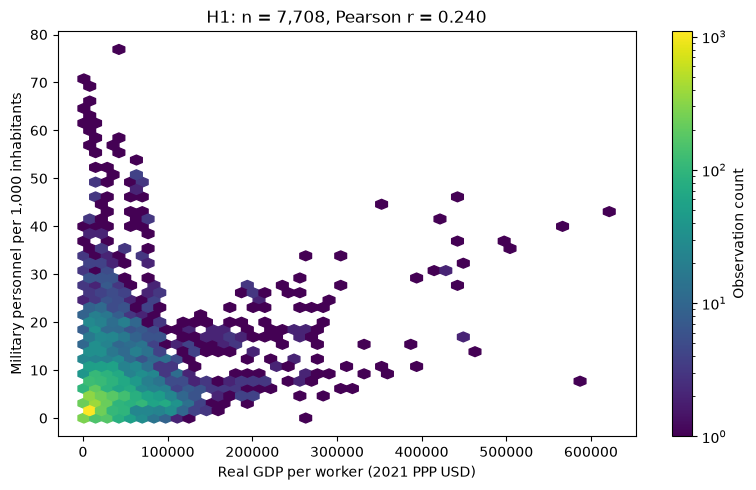

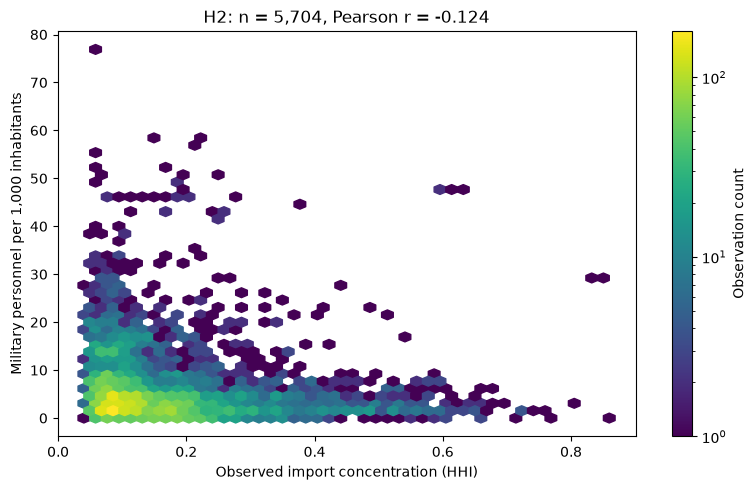

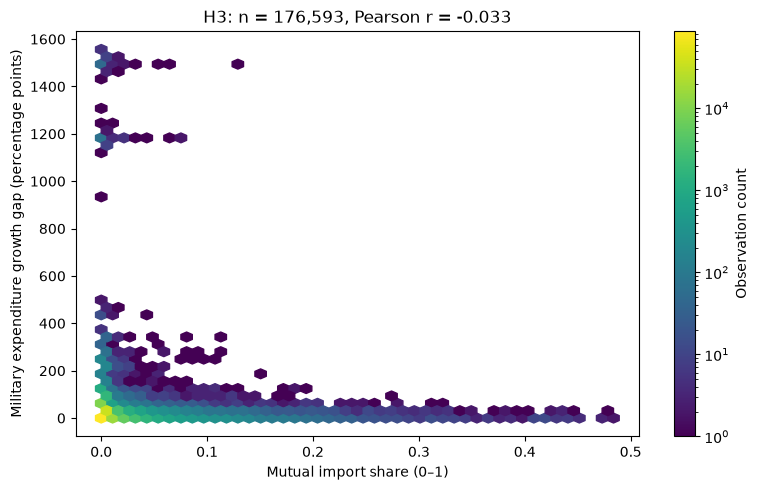

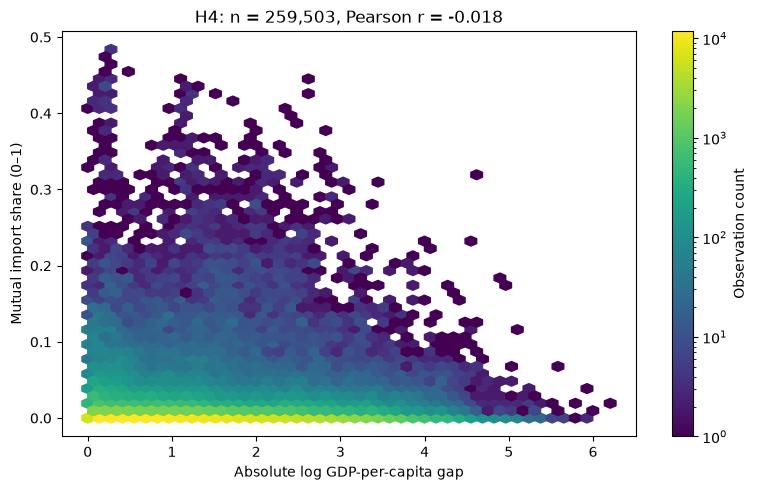

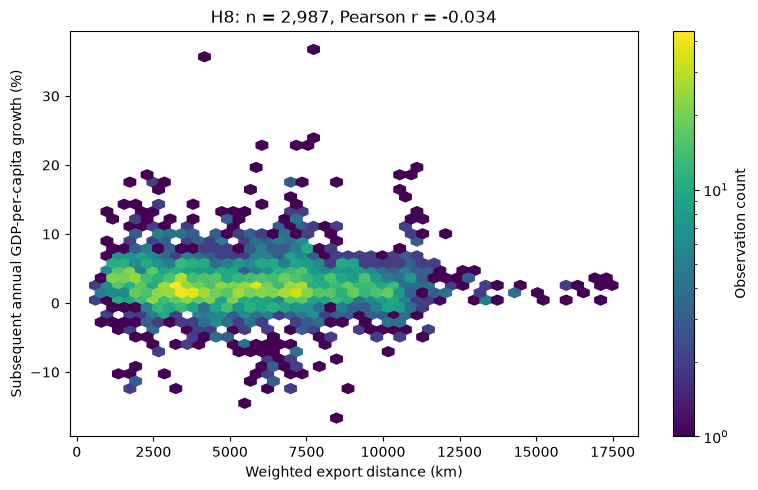

In [46]:
labels = {
    "productivity": "Real GDP per worker (2021 PPP USD)",
    "military_per_1000": "Military personnel per 1,000 inhabitants",
    "import_hhi_observed": "Observed import concentration (HHI)",
    "mutual_import_share": "Mutual import share (0–1)",
    "military_growth_gap_pp": "Military expenditure growth gap (percentage points)",
    "wealth_gap_log": "Absolute log GDP-per-capita gap",
    "export_distance_observed_km": "Weighted export distance (km)",
    "growth_next_5y_pct": "Subsequent annual GDP-per-capita growth (%)"
}

for name, (df, x, y, erwartung) in analysen.items():

    pairs = df[[x, y]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    r = ergebnisse.loc[
        ergebnisse["Hypothese"] == name, "Pearson_r"
    ].iloc[0]

    fig, ax = plt.subplots(figsize=(8, 5))

    plot = ax.hexbin(
        pairs[x],
        pairs[y],
        gridsize=45,
        mincnt=1,
        bins="log",
        cmap="viridis"
    )

    fig.colorbar(plot, ax=ax, label="Observation count")

    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])
    ax.set_title(
        f"{name}: n = {len(pairs):,}, Pearson r = {r:.3f}"
    )

    fig.tight_layout()
    plt.show()

In [47]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

ausgabeordner = Path("Ergebnisse")
ausgabeordner.mkdir(exist_ok=True)

zeitpunkt = datetime.now(ZoneInfo("Europe/Berlin"))
zeitstempel = zeitpunkt.strftime("%Y-%m-%d_%H-%M-%S_%f")

dateipfad = ausgabeordner / f"Analyseergebnisse_{zeitstempel}.xlsx"

# "xb" verhindert, dass eine vorhandene Datei überschrieben wird.
with dateipfad.open("xb") as datei:
    ergebnisse.to_excel(
        datei,
        sheet_name="Korrelationen",
        index=False,
        engine="openpyxl"
    )

print(f"Ergebnisse gespeichert:\n{dateipfad.resolve()}")

Ergebnisse gespeichert:
/Users/jannis.hardt/Documents/VS Code/Integrationsseminar/Ergebnisse/Analyseergebnisse_2026-10-15_14-59-21_691025.xlsx
